# 10 — Modelos Estatisticos Avancados

**Objetivos de aprendizagem:** interpretar GLMs para respostas de contagem e binárias e diagnosticar adequação

**Pré-requisitos:** Notebooks 03, 06–08

**Origem:** Aprofundamento novo, além dos slides; regressão preditiva aprofundada permanece em Aprendizado de Máquina. Conteúdos adicionais estão identificados como **Aprofundamento**.

**Convenção:** `datasets/` reúne dados de entrada; `outputs/` reúne resultados. Dados inventados para demonstrações são sempre identificados como *sintéticos*.

### Materiais complementares

- [Guia técnico: Modelos Estatisticos Avancados](./reference_materials/10_modelos_estatisticos_avancados.pdf)
- [Cheat sheet: Modelos Estatisticos Avancados](./cheat_sheets/cheat_sheet_modelos_estatisticos_avancados.pdf)


## Preparação do ambiente

Execute a célula abaixo. Os notebooks são independentes e não dependem de variáveis definidas em outros arquivos.

> **Resultados reproduzíveis:** gráficos PNG e tabelas CSV selecionados são gravados automaticamente em `outputs/` ao executar as células na ordem. Os arquivos em `datasets/` são preservados. Esta disciplina usa Matplotlib, não o renderer `iframe` do Plotly.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Execute o JupyterLab com o diretório desta disciplina como raiz.
BASE = Path.cwd()
DATASETS = BASE / "datasets"
OUTPUTS = BASE / "outputs"
DATASETS.mkdir(parents=True, exist_ok=True)
OUTPUTS.mkdir(parents=True, exist_ok=True)

def ler_dataset(nome):
    caminho = DATASETS / nome
    if not caminho.is_file():
        raise FileNotFoundError(f"Dataset não encontrado: {caminho}. Abra o JupyterLab na raiz da disciplina.")
    return pd.read_csv(caminho)

RNG = np.random.default_rng(42)

## 1. Estrutura de um GLM

GLMs relacionam média da resposta a um preditor linear por uma função de ligação e assumem uma família probabilística. Regressões logística e de Poisson são GLMs; um modelo bem ajustado não demonstra causalidade.

In [2]:
import statsmodels.api as sm
x=RNG.uniform(0,5,250)
dados=pd.DataFrame({'x':x})
print('Exemplos de ligações: log para Poisson; logit para Binomial')

Exemplos de ligações: log para Poisson; logit para Binomial


## 2. Regressão de Poisson para contagens

Se Y é contagem, `log(E[Y|X]) = β0+β1 X`. Então `exp(β1)` é uma razão multiplicativa de contagens médias por unidade de X, mantendo outros termos constantes. Taxas por exposição usam offset log(exposição).

In [3]:
mu=np.exp(.3+.25*x);contagens=RNG.poisson(mu) # dados sintéticos
X=sm.add_constant(dados[['x']]);m_poi=sm.GLM(contagens,X,family=sm.families.Poisson()).fit()
print(m_poi.params)
print('razão de taxas por unidade X:',np.exp(m_poi.params['x']))
print('AIC:',m_poi.aic)

const    0.364200
x        0.229456
dtype: float64
razão de taxas por unidade X: 1.2579154075717782
AIC: 918.2473273085562


## 3. Diagnóstico de sobredispersão

Na Poisson, Var(Y|X)=E[Y|X]. Se a variância condicional exceder substancialmente a média, uma hipótese do modelo pode estar inadequada. O diagnóstico depende do desenho e de como a heterogeneidade foi modelada.

In [4]:
razao=m_poi.pearson_chi2/m_poi.df_resid
print('Qui² de Pearson / gl residuais:',razao)
print('Deviance / gl residuais:',m_poi.deviance/m_poi.df_resid)

Qui² de Pearson / gl residuais: 1.0476255007458488
Deviance / gl residuais: 1.080551294032131


## 4. Binomial negativa como alternativa

O GLM binomial negativo permite variância maior que a média. Nesta implementação o parâmetro `alpha` da família é fixado; estimá-lo requer outro procedimento. Comparações de ajuste exigem modelos adequados e critérios consistentes.

In [5]:
nb=sm.GLM(contagens,X,family=sm.families.NegativeBinomial(alpha=1.0)).fit()
print('Coeficientes NB (alpha fixo):',nb.params.to_dict())
print('AIC NB:',nb.aic)

Coeficientes NB (alpha fixo): {'const': 0.379520885025052, 'x': 0.22376965239586089}
AIC NB: 1061.948365398119


## 5. Modelo binomial: interpretação estatística

No modelo logit, `log(p/(1−p))=β0+β1X`. `exp(β1)` é razão de odds, **não** razão de probabilidades. Treino de classificadores, validação cruzada e métricas preditivas aprofundadas ficam em Machine Learning.

In [6]:
prob=1/(1+np.exp(-(-1.5+.6*x)))
y=RNG.binomial(1,prob) # sintético
model_logit=sm.GLM(y,X,family=sm.families.Binomial()).fit()
print('coeficiente X:',model_logit.params['x'],'odds ratio:',np.exp(model_logit.params['x']))
print('intervalo 95% de odds ratio:',np.exp(model_logit.conf_int().loc['x']).to_numpy())

coeficiente X: 0.5219929931055021 odds ratio: 1.6853832619533304
intervalo 95% de odds ratio: [1.385528   2.05013304]


In [7]:
# Exportação reproduzível para outputs/ (dados e resultados didáticos)
pd.DataFrame({'modelo':['poisson','binomial_negativa_alpha_fixo','logistico'],'aic':[m_poi.aic,nb.aic,model_logit.aic], 'observacoes':[m_poi.nobs,nb.nobs,model_logit.nobs]}).to_csv(OUTPUTS / '10_comparacao_modelos.csv',index=False,encoding='utf-8-sig')
pd.DataFrame({'x':x,'contagens_observadas':contagens,'contagens_ajustadas_poisson':m_poi.fittedvalues,'residuo_pearson':m_poi.resid_pearson}).to_csv(OUTPUTS / '10_diagnostico_poisson.csv',index=False,encoding='utf-8-sig')
print('Resultados exportados em:', OUTPUTS)

Resultados exportados em: /run/media/eduardo/Backup/Faculdades/PUC - CIENCIA DE DADOS/PUC/02_Disciplinas/03_statistics/outputs


## 6. Resíduos e comparação de modelos

AIC compara compromisso entre ajuste e complexidade para modelos construídos sobre os *mesmos dados*. Diagnósticos requerem atenção a influência, resíduos, especificação, dependência e possíveis variáveis omitidas.

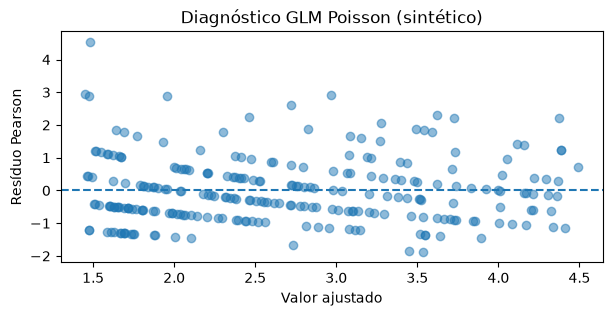

In [8]:
fig,ax=plt.subplots(figsize=(7,3));ax.scatter(m_poi.fittedvalues,m_poi.resid_pearson,alpha=.5);ax.axhline(0,ls='--');ax.set(xlabel='Valor ajustado',ylabel='Resíduo Pearson',title='Diagnóstico GLM Poisson (sintético)');fig.savefig(OUTPUTS / '10_diagnostico_residuos_poisson.png', dpi=160, bbox_inches='tight');plt.show()

### Exercício resolvido — Transformar coeficiente em razão

**Solução comentada:**

In [9]:
beta=.2;rr=np.exp(beta)
print('razão multiplicativa por +1 em X:',rr)
assert rr>1

razão multiplicativa por +1 em X: 1.2214027581601699


**Interpretação:** Um coeficiente de 0,2 em ligação log corresponde a aproximadamente 22% de aumento na média da resposta, condicional ao modelo, não a 0,2 eventos adicionais.

## Erros comuns e limites

Não confunda odds com probabilidade, p-valor de coeficiente com capacidade preditiva nem critério AIC com prova causal. Ajuste e seleção devem respeitar a distribuição da resposta e o desenho dos dados.

## Consulta Rápida

`sm.GLM(y,X,family=sm.families.Poisson()).fit()` · `sm.GLM(y,X,family=sm.families.Binomial()).fit()` · `np.exp(coef)` · `resultado.conf_int()` · `resultado.aic`.

## Autoavaliação

Antes de seguir, explique com suas palavras: **qual é a pergunta estatística, qual método responde a ela, quais pressupostos devem ser verificados e o que não podemos concluir?**

## Aprofundamento v2 — Diagnóstico de GLMs e validação fora da amostra

Para contagens, a função de ligação log implica `E[Y|X]=exp(Xβ)`; `exp(β)` é uma **razão multiplicativa de taxas/médias**, não uma diferença absoluta. Para respostas binárias, `exp(β)` em ligação logit representa **odds ratio**, não risco relativo.

Um GLM binomial pode exibir separação perfeita; modelos de contagem podem ter sobredispersão e excesso de zeros. AIC é comparação relativa entre modelos ajustados à mesma resposta e amostra, e não substitui diagnóstico nem validação.

In [10]:
import statsmodels.api as sm
rng_glm=np.random.default_rng(2026)
x_glm=rng_glm.normal(size=320)
mu_glm=np.exp(.2+.35*x_glm)
y_glm=rng_glm.poisson(mu_glm)
indices=rng_glm.permutation(len(y_glm))
train=indices[:240];test=indices[240:]
X_glm=sm.add_constant(x_glm)
modelo_glm=sm.GLM(y_glm[train],X_glm[train],family=sm.families.Poisson()).fit()
prev_glm=modelo_glm.predict(X_glm[test])
mae_glm=np.mean(np.abs(y_glm[test]-prev_glm))
print('MAE em amostra de teste simulada:',round(mae_glm,3))
print('Razão multiplicativa estimada para +1 em x:',round(np.exp(modelo_glm.params[1]),3))
assert (prev_glm>0).all() and mae_glm>=0

MAE em amostra de teste simulada: 0.955
Razão multiplicativa estimada para +1 em x: 1.478


### Exercício resolvido

**Pergunta:** um coeficiente logit é `0,7`. Podemos afirmar que o risco dobrou?

**Solução:** não. `exp(0,7)≈2,01` corresponde às *odds* multiplicadas por aproximadamente 2, e não necessariamente à probabilidade ou ao risco relativo duplicado.